# 6. Boundary value problems

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/notebooks/06_boundary_value_problems.ipynb)

*Companion to Chapter 7 of L. N. Trefethen, Spectral Methods in MATLAB (SIAM, 2000).*

Notebook 5 built a matrix that differentiates. This notebook turns it round: given an equation
for the derivatives of an unknown function and its values at the two ends of an interval, find
the function. Replacing each derivative by a matrix turns a differential equation into a set
of algebraic equations, and the only new idea needed is how to put the boundary conditions in.

- Dirichlet conditions: which rows and columns to drop, and why
- non-zero boundary values and variable coefficients
- a nonlinear problem solved by Newton's method, and a solution curve that turns back
- two space dimensions with the Kronecker product

**Worked examples:** the effectiveness factor of a catalyst slab; the thermal explosion limit
of a reactive solid; the friction factor of laminar flow in a square duct.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dct                 # discrete cosine transform, used only inside clenshaw_curtis (notebooks 7 and 10)
from scipy.optimize import brentq, minimize_scalar

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# cheb(N) from notebook 5
def cheb(N):
    """Chebyshev differentiation matrix D, (N+1) x (N+1), and the points x_j = cos(jπ/N)."""
    if N == 0:
        return np.zeros((1, 1)), np.ones(1)
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    c = np.where((j == 0) | (j == N), 2.0, 1.0) * (-1.0) ** j
    dx = x[:, None] - x[None, :]
    D = (c[:, None] / c[None, :]) / (dx + np.eye(N + 1))        # the identity avoids 0/0 on the diagonal
    D -= np.diag(D.sum(axis=1))                                  # diagonal from the zero row sums
    return D, x

## 6.1 Dirichlet conditions: drop two rows and two columns

**Problem.** A wall occupies $-1 \le x \le 1$. Both faces are held at the reference temperature
and heat is released inside, mostly near the mid-plane. In dimensionless form

$$u''(x) = -\operatorname{sech}^2(3x),\qquad u(-1) = u(1) = 0 .$$

Because $(\ln\cosh 3x)'' = 9\operatorname{sech}^2 3x$, the exact solution is
$u = \tfrac19\big(\ln\cosh 3 - \ln\cosh 3x\big)$, which we keep for checking.

**By hand.** Store the unknown as its values $u_0, \dots, u_N$ at the Chebyshev points and write
the equation at every point: $D^2\mathbf{u} = \mathbf{f}$, which is $N+1$ equations. This
system cannot be solved as it stands. $D^2$ is singular (it sends both $u = 1$ and $u = x$ to
zero), which is the discrete form of a familiar fact: $u'' = f$ fixes $u$ only up to $a + bx$,
and the two boundary conditions supply the two missing constants.

Recall the ordering of the points: **index 0 is $x = +1$ and index $N$ is $x = -1$**. The
boundary conditions say $u_0 = 0$ and $u_N = 0$, so these two values are not unknowns at all.
Two changes follow.

- **Drop the first and last columns** of $D^2$. Column $j$ multiplies $u_j$, and $u_0 = u_N = 0$
  contribute nothing.
- **Drop the first and last rows.** Row $i$ is the differential equation written at $x_i$. With
  only $N-1$ unknowns left we can keep only $N-1$ equations, and the ones to give up are those
  at the two boundary points, where the boundary condition takes the place of the equation.

What remains is a square system for the interior values $u_1, \dots, u_{N-1}$. In NumPy the
interior block is `D2[1:N, 1:N]`.

In [3]:
N = 4
D, x = cheb(N)
D2 = D @ D
print("points:", np.round(x, 3), "  (index 0 is x = +1, index N is x = -1)\n")
print("full D2, 5 x 5:\n", np.round(D2, 1), "\n")
print("interior block D2[1:N, 1:N], 3 x 3, acting on the unknowns u_1, u_2, u_3:\n", np.round(D2[1:N, 1:N], 1))
print("\nrank of the full matrix:", np.linalg.matrix_rank(D2), "of 5.   condition number of the interior block:",
      round(np.linalg.cond(D2[1:N, 1:N]), 1))

points: [ 1.     0.707  0.    -0.707 -1.   ]   (index 0 is x = +1, index N is x = -1)

full D2, 5 x 5:
 [[ 17.  -28.5  18.  -11.5   5. ]
 [  9.2 -14.    6.   -2.    0.8]
 [ -1.    4.   -6.    4.   -1. ]
 [  0.8  -2.    6.  -14.    9.2]
 [  5.  -11.5  18.  -28.5  17. ]] 

interior block D2[1:N, 1:N], 3 x 3, acting on the unknowns u_1, u_2, u_3:
 [[-14.   6.  -2.]
 [  4.  -6.   4.]
 [ -2.   6. -14.]]

rank of the full matrix: 3 of 5.   condition number of the interior block: 8.1


The full matrix has rank 3: it cannot be inverted. The interior block can. Solving the wall
problem takes four lines.

In [4]:
def solve_wall(N):
    D, x = cheb(N)
    D2 = D @ D
    u = np.zeros(N + 1)                                            # u[0] and u[N] stay zero: the boundary values
    u[1:N] = np.linalg.solve(D2[1:N, 1:N], -1 / np.cosh(3 * x[1:N]) ** 2)
    return x, u

wall_exact = lambda x: (np.log(np.cosh(3)) - np.log(np.cosh(3 * x))) / 9

print("  N    largest error")
for N in (8, 16, 24, 32, 40):
    x, u = solve_wall(N)
    print(f"{N:3d}    {np.abs(u - wall_exact(x)).max():.1e}")

x, u = solve_wall(40)
assert np.abs(u - wall_exact(x)).max() < 5e-11

  N    largest error
  8    4.4e-03
 16    9.3e-06
 24    4.8e-08
 32    4.3e-10
 40    4.8e-12


**Verify.** Every eight points added reduce the error by a factor of ninety or more:
geometric convergence, as for differentiation in notebook 5. Forty points give eleven
digits of the temperature everywhere in the wall.

## 6.2 Worked example: reaction and diffusion in a catalyst slab

**Problem.** A reactant diffuses into a porous catalyst slab from both faces and is consumed
by a first-order reaction. With $x$ scaled by the half-thickness $L$ and the concentration
$\theta$ scaled by its value at the faces,

$$\theta'' = \phi^2\theta,\qquad \theta(\pm1) = 1,\qquad \phi = L\sqrt{k/D_e}\ \text{(the Thiele modulus)} .$$

The exact solution is $\theta = \cosh\phi x/\cosh\phi$. The design quantity is the
**effectiveness factor** $\eta$: the actual reaction rate divided by the rate the slab would
have if the concentration were 1 throughout. Integrating the equation once shows that the
reactant consumed equals the diffusive flow through the faces, which gives
$\eta = \theta'(1)/\phi^2 = \tanh\phi/\phi$.

**By hand.** Two things are new. The operator is now $A = D^2 - \phi^2 I$, which changes
nothing in the procedure. And the boundary values are 1, not 0, so the boundary columns no
longer vanish. Write row $i$ of $A\boldsymbol\theta = 0$ for an interior point and split the
sum into unknown and known parts:

$$\sum_{j=1}^{N-1} A_{ij}\theta_j \;=\; -A_{i0}\,\theta_0 - A_{iN}\,\theta_N ,\qquad i = 1, \dots, N-1 .$$

The known boundary values, multiplied by their columns, **move to the right-hand side**. The
matrix on the left is the same interior block as before.

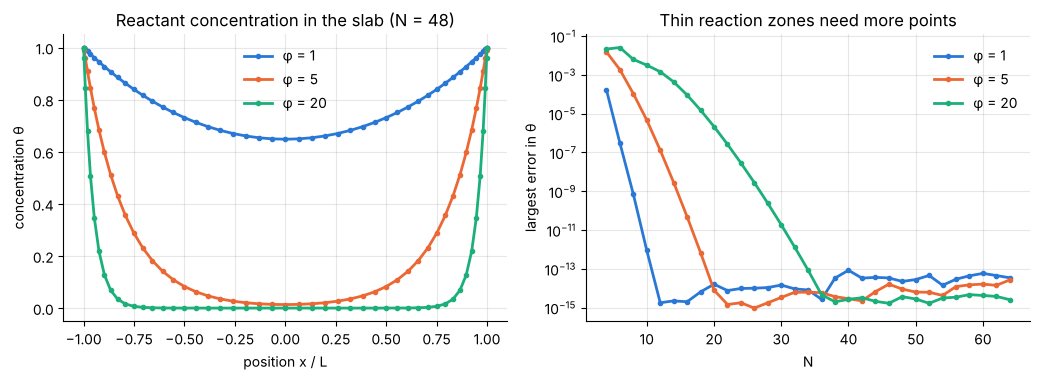

In [5]:
def catalyst_slab(phi, N):
    """Concentration profile and effectiveness factor for a first-order reaction in a slab."""
    D, x = cheb(N)
    A = D @ D - phi**2 * np.eye(N + 1)
    theta = np.ones(N + 1)                                         # theta[0] = theta[N] = 1: the two faces
    boundary = [0, N]                                              # index 0 is x = +1, index N is x = -1
    theta[1:N] = np.linalg.solve(A[1:N, 1:N], -A[1:N, boundary] @ theta[boundary])
    eta = (D @ theta)[0] / phi**2                                  # row 0 of D gives the gradient at x = +1
    return x, theta, eta

N_values = np.arange(4, 65, 2)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9))
for phi in (1, 5, 20):
    x, theta, _ = catalyst_slab(phi, 48)
    axes[0].plot(x, theta, "o-", ms=3, label=f"φ = {phi}")
    errors = []
    for N in N_values:
        x, theta, _ = catalyst_slab(phi, N)
        errors.append(np.abs(theta - np.cosh(phi * x) / np.cosh(phi)).max())
    axes[1].semilogy(N_values, errors, "o-", ms=3, label=f"φ = {phi}")
axes[0].set(xlabel="position x / L", ylabel="concentration θ", title="Reactant concentration in the slab (N = 48)")
axes[0].legend(frameon=False, loc="upper center")
axes[1].set(xlabel="N", ylabel="largest error in θ", title="Thin reaction zones need more points")
axes[1].legend(frameon=False, loc="upper right")
fig.tight_layout()

**Verify** the profile and the effectiveness factor for $\phi = 5$, and count the points each
Thiele modulus needs.

In [6]:
x, theta, eta = catalyst_slab(5.0, 24)
print(f"φ = 5, N = 24:  η = {eta:.12f}   exact tanh(φ)/φ = {np.tanh(5.0) / 5.0:.12f}")
assert abs(eta - np.tanh(5.0) / 5.0) < 1e-10
assert np.abs(theta - np.cosh(5 * x) / np.cosh(5)).max() < 1e-12

def points_for(phi, target=1e-10):
    return next(N for N in N_values if abs(catalyst_slab(phi, N)[2] - np.tanh(phi) / phi) < target)

needed = {phi: points_for(phi) for phi in (1, 5, 20)}
print("points needed for an error in η below 1e-10:", {f"φ = {phi}": f"N = {N}" for phi, N in needed.items()})
assert needed[1] < needed[5] < needed[20] <= 40

φ = 5, N = 24:  η = 0.199981840853   exact tanh(φ)/φ = 0.199981840853
points needed for an error in η below 1e-10: {'φ = 1': 'N = 10', 'φ = 5': 'N = 18', 'φ = 20': 'N = 30'}


All three curves fall at least geometrically to the rounding level. A large Thiele modulus
means the reaction is fast compared with diffusion: the reactant is used up in a layer of
thickness about $L/\phi$ next to each face and the interior of the slab is wasted
($\eta \approx 1/\phi$).
Resolving that layer costs points, but not many, because the Chebyshev grid is densest exactly
where the layer is. For a slab with $\phi = 20$, whose reaction zone is 5 % of the half-thickness,
30 points give $\eta$ with an error below $10^{-10}$.

## 6.3 Variable coefficients

**Problem.** A wall is made of a graded material whose conductivity rises smoothly from one
face to the other, $k(x) = e^{\beta x}$, and is heated uniformly at the rate $q$:

$$\big(k(x)\,u'\big)' = -q,\qquad u(\pm1) = 0 .$$

Where is the hottest point, and how is the heat shared between the two faces?

**By hand.** Multiplication of a grid function by $k(x)$ is the diagonal matrix
$K = \operatorname{diag}(k(x_j))$. Reading the operator from right to left (differentiate,
multiply by $k$, differentiate again) gives $A = D K D$, and the boundary conditions are imposed
as in 6.1. A variable coefficient costs one extra matrix product.

For checking, integrate once: $k u' = q\,(c - x)$, so the gradient vanishes at $x = c$, the hot
spot. A second integration and the two boundary conditions give
$u = q\,e^{-\beta x}\big[(x - c)/\beta + 1/\beta^2\big] + \text{const}$ with
$c = 1/\beta - \coth\beta$.

largest error in u: 1.8e-15
heat leaving through x = +1: 1.313035   through x = -1: 0.686965   total: 2.000000


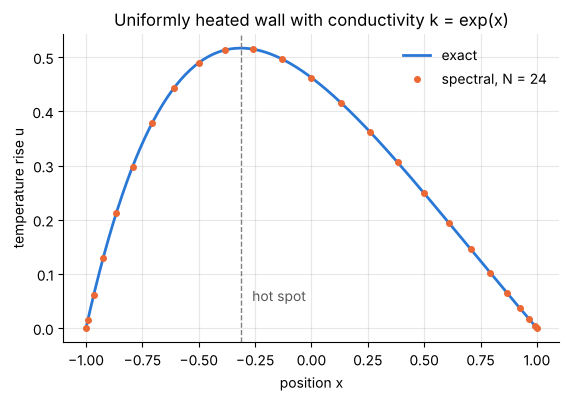

In [7]:
beta, q = 1.0, 1.0
N = 24
D, x = cheb(N)
k = np.exp(beta * x)
A = D @ np.diag(k) @ D
u = np.zeros(N + 1)
u[1:N] = np.linalg.solve(A[1:N, 1:N], -q * np.ones(N - 1))

c = 1 / beta - 1 / np.tanh(beta)
shape = lambda x: q * np.exp(-beta * x) * ((x - c) / beta + 1 / beta**2)
u_exact = shape(x) - shape(1.0)
flux = -k * (D @ u)                                                # heat flux in the +x direction
out_right, out_left = flux[0], -flux[N]                            # index 0 is the face x = +1, index N the face x = -1

print(f"largest error in u: {np.abs(u - u_exact).max():.1e}")
print(f"heat leaving through x = +1: {out_right:.6f}   through x = -1: {out_left:.6f}   total: {out_right + out_left:.6f}")
assert np.abs(u - u_exact).max() < 1e-12
assert abs(out_right + out_left - 2 * q) < 1e-11                   # energy balance: all the heat generated leaves
assert abs(out_right - q * (1 - c)) < 1e-11

fine = np.linspace(-1, 1, 300)
fig, ax = plt.subplots()
ax.plot(fine, shape(fine) - shape(1.0), label="exact")
ax.plot(x, u, "o", ms=4, label=f"spectral, N = {N}")
ax.axvline(c, color="0.5", lw=1, ls="--")
ax.annotate("hot spot", xy=(c, 0.05), xytext=(c + 0.05, 0.05), color="0.35")
ax.set(xlabel="position x", ylabel="temperature rise u", title="Uniformly heated wall with conductivity k = exp(x)")
ax.legend(frameon=False, loc="upper right");

The two fluxes add up to the heat generated, $2q$, to eleven digits: the discrete solution
satisfies the energy balance. The hot spot sits at $x = -0.31$, displaced towards the poorly
conducting face, and about two thirds of the heat leaves through the conducting face. A
designer who assumed a uniform conductivity would put the peak temperature in the wrong place.

## 6.4 A nonlinear problem: thermal explosion

**Problem.** A slab of material that reacts exothermically (a stockpile of coal, a stored
reactive chemical, a battery electrode) is cooled at its faces. Heat is produced at a rate that
grows exponentially with temperature and is removed by conduction. In the classical model of
Frank-Kamenetskii the dimensionless temperature rise $u$ obeys

$$u'' + \delta\,e^{u} = 0,\qquad u(\pm1) = 0 ,$$

where $\delta$ compares heat production with conduction and is proportional to the square of
the slab thickness. For which $\delta$ does a steady temperature exist?

Mathematicians know this equation as the Bratu problem, hence the names in the code. It has an
exact solution, found by multiplying by $u'$ and integrating:
$u(x) = 2\ln\dfrac{\cosh\kappa}{\cosh\kappa x}$, where $\kappa$ is a root of
$\delta = 2\kappa^2/\cosh^2\kappa$. The centre temperature is $u(0) = 2\ln\cosh\kappa$.

**By hand: Newton's method.** At the interior points the unknowns must satisfy
$\mathbf{F}(\mathbf{u}) = D^2\mathbf{u} + \delta e^{\mathbf{u}} = 0$, which is a set of
nonlinear algebraic equations. Linearize about the current guess: a small change
$\mathbf{s}$ changes $\mathbf{F}$ by $J\mathbf{s}$, where the Jacobian is

$$J = D^2 + \delta\,\operatorname{diag}(e^{\mathbf{u}}) .$$

Each Newton step solves the **linear** boundary value problem $J\mathbf{s} = -\mathbf{F}$ by the
method of 6.1 and replaces $\mathbf{u}$ by $\mathbf{u} + \mathbf{s}$. The boundary values of
$u$ are zero and stay zero, so the correction $\mathbf{s}$ has zero boundary values too.

In [8]:
def bratu_newton(delta, N, start, steps=7):
    """Newton iteration for u'' + δ exp(u) = 0, u(±1) = 0. Returns x, u and the residual history."""
    D, x = cheb(N)
    D2 = (D @ D)[1:N, 1:N]
    u = start(x[1:N])
    history = []
    for _ in range(steps):
        F = D2 @ u + delta * np.exp(u)
        history.append(np.abs(F).max())
        u = u - np.linalg.solve(D2 + delta * np.diag(np.exp(u)), F)
    return x, np.concatenate(([0.0], u, [0.0])), history

x, u, history = bratu_newton(0.5, 24, start=np.zeros_like)
for step, residual in enumerate(history):
    print(f"step {step}:  largest residual = {residual:.1e}")

step 0:  largest residual = 5.0e-01
step 1:  largest residual = 2.8e-02
step 2:  largest residual = 6.3e-05
step 3:  largest residual = 2.9e-10
step 4:  largest residual = 8.6e-14
step 5:  largest residual = 3.3e-14
step 6:  largest residual = 3.6e-14


**Verify.** The residual is roughly squared at every step until rounding stops it: 0.5,
$3\times10^{-2}$, $6\times10^{-5}$, $3\times10^{-10}$. This **quadratic convergence** is the
signature of a correct Jacobian. With a mistake in the Jacobian the iteration usually still
converges, but only linearly, so printing the residuals is a cheap test of the derivation.

In [9]:
assert all(history[i + 1] < history[i] ** 1.8 for i in range(3)) and history[4] < 1e-11

kappa_low = brentq(lambda t: 2 * t**2 / np.cosh(t) ** 2 - 0.5, 0.0, 1.19)        # the smaller root: lower branch
bratu_exact = lambda x, t: 2 * np.log(np.cosh(t) / np.cosh(t * x))
print(f"largest error against the exact solution: {np.abs(u - bratu_exact(x, kappa_low)).max():.1e}")
assert np.abs(u - bratu_exact(x, kappa_low)).max() < 1e-11

largest error against the exact solution: 1.3e-13


## 6.5 Following the solution curve round the turning point

The function $2\kappa^2/\cosh^2\kappa$ rises from zero, reaches a maximum and falls back to
zero. So for a small $\delta$ there are **two** values of $\kappa$, hence two steady solutions,
and beyond the maximum there are none. Newton's method started from zero found the cooler one.

Finding the maximum by solving for larger and larger $\delta$ works badly: close to the turning
point the Jacobian is nearly singular, and past it Newton's method fails without telling us
whether the solution has ceased to exist or the starting guess was poor.

**By hand.** Change the question. Prescribe the centre temperature, $u(0) = u_c$, and ask which
$\delta$ produces it. Along the solution curve $u_c$ increases steadily, so this problem has
exactly one solution for each $u_c$ and no turning point. There is one more unknown, $\delta$,
and one more equation, $u_{N/2} = u_c$ (with $N$ even, the middle grid point is $x = 0$). The
Newton system grows by one row and one column:

$$\begin{pmatrix} D^2 + \delta\operatorname{diag}(e^{\mathbf{u}}) & e^{\mathbf{u}} \\ \mathbf{e}_{\text{mid}}^{T} & 0 \end{pmatrix}
\begin{pmatrix} \mathbf{s} \\ s_\delta \end{pmatrix} = -\begin{pmatrix} D^2\mathbf{u} + \delta e^{\mathbf{u}} \\ u_{\text{mid}} - u_c \end{pmatrix} .$$

The last column is $\partial\mathbf{F}/\partial\delta = e^{\mathbf{u}}$, and the last row picks
out the centre value.

In [10]:
def bratu_centre(u_c, N=40, guess=None):
    """Solve u'' + δ exp(u) = 0, u(±1) = 0 with the centre value u(0) = u_c prescribed. Returns δ, x, u."""
    D, x = cheb(N)
    D2 = (D @ D)[1:N, 1:N]
    mid = N // 2 - 1                                               # position of x = 0 among the interior points
    u, delta = (u_c * (1 - x[1:N] ** 2), u_c / (1 + u_c)) if guess is None else guess
    J = np.zeros((N, N))
    J[N - 1, mid] = 1.0
    for _ in range(40):
        F = np.append(D2 @ u + delta * np.exp(u), u[mid] - u_c)
        if np.abs(F).max() < 1e-12:
            break
        J[:N - 1, :N - 1] = D2 + delta * np.diag(np.exp(u))
        J[:N - 1, N - 1] = np.exp(u)
        step = np.linalg.solve(J, -F)
        u, delta = u + step[:-1], delta + step[-1]
    return delta, x, np.concatenate(([0.0], u, [0.0]))

uc_values = np.linspace(0.02, 5.0, 250)
delta_values, guess = [], None
for u_c in uc_values:                                              # each solution is the starting guess for the next
    delta, x, u = bratu_centre(u_c, guess=guess)
    delta_values.append(delta)
    guess = (u[1:-1], delta)
delta_values = np.array(delta_values)

**Verify** the whole curve against the exact relation between $u_c = 2\ln\cosh\kappa$ and
$\delta$, then locate the turning point by maximizing $\delta(u_c)$.

In [11]:
kappa_of_uc = np.arccosh(np.exp(uc_values / 2))
assert np.abs(delta_values - 2 * kappa_of_uc**2 / np.cosh(kappa_of_uc) ** 2).max() < 1e-9

peak = minimize_scalar(lambda u_c: -bratu_centre(u_c)[0], bounds=(0.8, 1.6), method="bounded", options={"xatol": 1e-9})
uc_crit, delta_c = peak.x, -peak.fun
kappa_c = brentq(lambda t: t * np.tanh(t) - 1, 1.0, 1.5)           # the maximum of 2κ²/cosh²κ is where κ tanh κ = 1
print(f"turning point:  δ_c = {delta_c:.6f}   centre temperature u(0) = {uc_crit:.6f}")
print(f"exact:          δ_c = {2 * kappa_c**2 / np.cosh(kappa_c) ** 2:.6f}   u(0) = {2 * np.log(np.cosh(kappa_c)):.6f}   κ_c = {kappa_c:.6f}")
assert abs(delta_c - 0.878458) < 1e-6 and abs(kappa_c - 1.199679) < 1e-6
assert abs(delta_c - 2 * kappa_c**2 / np.cosh(kappa_c) ** 2) < 1e-10
assert abs(uc_crit - 2 * np.log(np.cosh(kappa_c))) < 1e-5 and abs(uc_crit - 1.186842) < 1e-5

# the second, hotter solution for δ = 0.5: search the upper branch for the centre temperature that gives δ = 0.5
uc_hot = brentq(lambda u_c: bratu_centre(u_c)[0] - 0.5, uc_crit, 5.0, xtol=1e-12)
_, x_hot, u_hot = bratu_centre(uc_hot)
kappa_high = brentq(lambda t: 2 * t**2 / np.cosh(t) ** 2 - 0.5, 1.2, 5.0)
assert np.abs(u_hot - bratu_exact(x_hot, kappa_high)).max() < 1e-8

turning point:  δ_c = 0.878458   centre temperature u(0) = 1.186842
exact:          δ_c = 0.878458   u(0) = 1.186842   κ_c = 1.199679


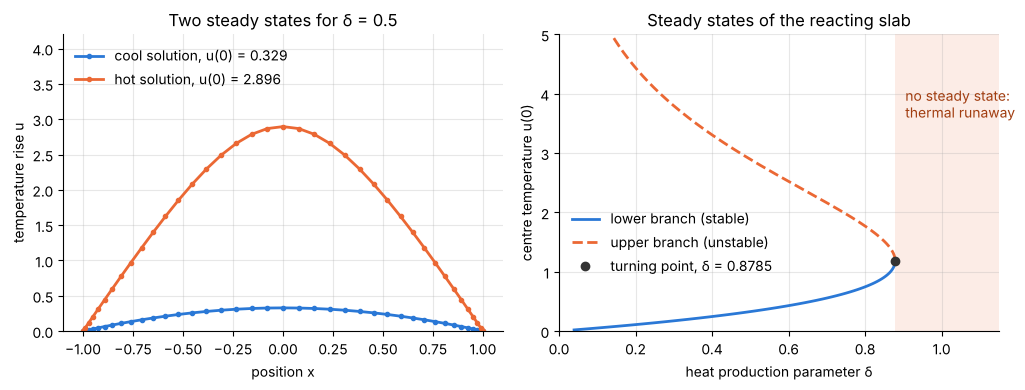

In [12]:
x_cool, u_cool, _ = bratu_newton(0.5, 40, start=np.zeros_like)
lower = uc_values <= uc_crit
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
axes[0].plot(x_cool, u_cool, "o-", ms=3, label=f"cool solution, u(0) = {u_cool.max():.3f}")
axes[0].plot(x_hot, u_hot, "o-", ms=3, label=f"hot solution, u(0) = {u_hot.max():.3f}")
axes[0].set(xlabel="position x", ylabel="temperature rise u", ylim=(0, 4.2), title="Two steady states for δ = 0.5")
axes[0].legend(frameon=False, loc="upper left")
axes[1].plot(delta_values[lower], uc_values[lower], label="lower branch (stable)")
axes[1].plot(delta_values[~lower], uc_values[~lower], "--", label="upper branch (unstable)")
axes[1].plot(delta_c, uc_crit, "o", color="0.2", label=f"turning point, δ = {delta_c:.4f}")
axes[1].axvspan(delta_c, 1.15, color="#eb6834", alpha=0.12, lw=0)
axes[1].annotate("no steady state:\nthermal runaway", xy=(0.905, 3.6), color="#a13d10")
axes[1].set(xlabel="heat production parameter δ", ylabel="centre temperature u(0)", xlim=(0, 1.15), ylim=(0, 5),
            title="Steady states of the reacting slab")
axes[1].legend(frameon=False, loc="center left", bbox_to_anchor=(0.0, 0.3))
fig.tight_layout()

The computed limit is $\delta_c = 0.878458$, at a centre temperature rise of 1.186842, in
agreement with the exact values to all digits shown.

What it means: $\delta$ grows with the square of the slab thickness and exponentially with the
surrounding temperature. Below $\delta_c$ conduction can carry away the heat of reaction and
the slab settles on the lower branch. (The upper branch is a steady state too, but an unstable
one: it marks the temperature disturbance needed to ignite the slab.) Above $\delta_c$ there is
**no steady state at all**: heat is produced faster than any temperature profile can conduct it
away, and the temperature runs away. Safe storage sizes for self-heating materials are set by
this number. Note that nothing dramatic happens to the lower-branch solution as the limit is
approached; the centre is only 1.19 units warmer than the surface when the solution ceases
to exist.

With this exponential heat source the curve has a single turning point. With the full Arrhenius
rate it bends back a second time at high temperature and becomes S-shaped (exercise 4).

## 6.6 Two space dimensions

**Problem.** Solve the Poisson equation $u_{xx} + u_{yy} = f(x, y)$ on the square
$[-1, 1]^2$ with $u = 0$ on the boundary.

**By hand.** Use the same Chebyshev grid in both directions. The interior unknowns form an
array $U$ of shape $(N-1)\times(N-1)$ with `U[i, j]` $= u(x_j, y_i)$: the row index counts in
$y$ and the column index in $x$, which is what `np.meshgrid` produces. To write a linear system
the array must be strung out into one long vector. `U.flatten()` does this **row by row**, so
unknown number $i\,(N-1) + j$ is `U[i, j]`, and the $x$ index runs fastest.

With that ordering, and $\tilde D^2$ standing for the interior block `D2[1:N, 1:N]`:

- $\partial^2/\partial x^2$ acts along each row of $U$ separately. In the long vector each row
  is a block of $N-1$ consecutive entries, so the matrix is block diagonal with a copy of
  $\tilde D^2$ in every block: $I \otimes \tilde D^2$, or `np.kron(I, D2)`.
- $\partial^2/\partial y^2$ couples entries with the same $j$ in different rows, which are
  $N-1$ places apart in the long vector. Its matrix is $\tilde D^2 \otimes I$, or
  `np.kron(D2, I)`: every entry of $\tilde D^2$ is spread out into a multiple of the identity.

The Laplacian is the sum, $L = I\otimes\tilde D^2 + \tilde D^2\otimes I$.

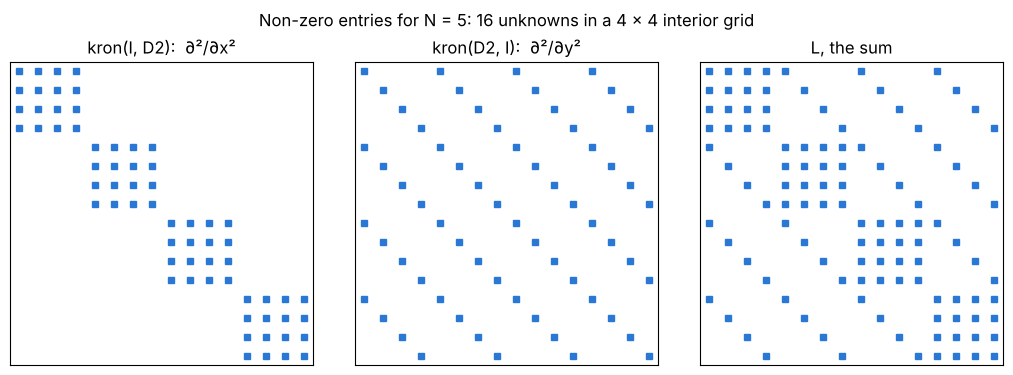

In [13]:
def laplacian_2d(N):
    """Laplacian on the interior Chebyshev points of the square, zero boundary values. Returns L and x."""
    D, x = cheb(N)
    D2 = (D @ D)[1:N, 1:N]
    I = np.eye(N - 1)
    return np.kron(I, D2) + np.kron(D2, I), x

D, x = cheb(5)
D2_small, I_small = (D @ D)[1:5, 1:5], np.eye(4)
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.7))
for ax, matrix, name in zip(axes, (np.kron(I_small, D2_small), np.kron(D2_small, I_small), laplacian_2d(5)[0]),
                            ("kron(I, D2):  ∂²/∂x²", "kron(D2, I):  ∂²/∂y²", "L, the sum")):
    ax.spy(matrix, markersize=5, color="#2a78d6")
    ax.set(title=name, xticks=[], yticks=[])
    ax.spines[["top", "right"]].set_visible(True)
    ax.grid(False)
fig.suptitle("Non-zero entries for N = 5: 16 unknowns in a 4 × 4 interior grid", y=1.0)
fig.tight_layout()

Each row of $L$ has $2(N-1) - 1$ non-zeros: a grid point is coupled to every point in its own
row and its own column of the grid, and to no others.

**Verify with a manufactured solution.** Choose a function that vanishes on the boundary, work
out its Laplacian by hand, solve with that as the right-hand side and compare. We take
$u = e^{x}\sin\pi x\,\cos\tfrac{\pi y}{2}$, for which
$\nabla^2 u = e^{x}\big[(1 - \tfrac54\pi^2)\sin\pi x + 2\pi\cos\pi x\big]\cos\tfrac{\pi y}{2}$.

In [14]:
N = 20
L, x = laplacian_2d(N)
X, Y = np.meshgrid(x[1:N], x[1:N])                                 # X[i, j] = x_j and Y[i, j] = y_i
u_manufactured = np.exp(X) * np.sin(np.pi * X) * np.cos(np.pi * Y / 2)
f = np.exp(X) * ((1 - 1.25 * np.pi**2) * np.sin(np.pi * X) + 2 * np.pi * np.cos(np.pi * X)) * np.cos(np.pi * Y / 2)

U = np.linalg.solve(L, f.flatten()).reshape(N - 1, N - 1)          # flatten and reshape use the same row-by-row order
print(f"N = {N}: {(N - 1) ** 2} unknowns, largest error {np.abs(U - u_manufactured).max():.1e}")
assert np.abs(U - u_manufactured).max() < 1e-11

N = 20: 361 unknowns, largest error 2.2e-15


The test function is not symmetric in $x$ and is different in $x$ and $y$, so it would expose
a confusion between the two directions or between the two ends of the interval.

## 6.7 Worked example: laminar flow in a square duct

**Problem.** In fully developed laminar flow along a duct the axial velocity $w$ satisfies
$\mu\nabla^2 w = -G$, where $G$ is the pressure drop per unit length, with $w = 0$ on the
walls. For a square duct of side $2a$, scale lengths by $a$ and velocity by $Ga^2/\mu$:

$$\nabla^2 u = -1\ \text{ on } [-1, 1]^2,\qquad u = 0\ \text{ on the walls}.$$

Find the flow rate, the centreline velocity and the friction factor.

**By hand.** The flow rate is $Q = \iint u\,dx\,dy$ and the mean velocity is $\bar u = Q/4$.
A force balance on a length of duct gives the mean wall shear stress,
$\bar\tau_w = G\,D_h/4$, with the hydraulic diameter $D_h = 4\times\text{area}/\text{perimeter} = 2a$.
The Fanning friction factor is $f = \bar\tau_w/(\tfrac12\rho\bar w^2)$ and the Reynolds number
is $Re = \rho\bar w D_h/\mu$, so their product is a pure number that depends only on the shape:

$$f\,Re = \frac{G\,D_h^2}{2\mu\bar w} = \frac{2}{\bar u} = \frac{8}{Q} .$$

The integral needs weights $w_j$ such that $\int_{-1}^{1} g\,dx \approx \sum_j w_j\,g(x_j)$ on
the Chebyshev points. These are the Clenshaw-Curtis weights, pasted here and derived in
notebook 10. In two dimensions the weight of the point $(x_j, y_i)$ is the product $w_i w_j$.

In [15]:
# clenshaw_curtis(N): weights w_j with ∫ f dx ≈ Σ w_j f(x_j) on the Chebyshev points; derived in notebook 10
def clenshaw_curtis(N):
    """Clenshaw-Curtis nodes (the Chebyshev points) and weights on [-1, 1]."""
    if N == 0:
        return np.ones(1), np.array([2.0])
    x = np.cos(np.pi * np.arange(N + 1) / N)
    moments = np.zeros(N + 1)
    even = np.arange(0, N + 1, 2)
    moments[even] = 2 / (1 - even.astype(float) ** 2)
    w = dct(moments, type=1) / N
    w[0] /= 2
    w[N] /= 2
    return x, w

def square_duct(N):
    """Velocity on the interior points, flow rate and centre velocity for the square duct (N even)."""
    L, x = laplacian_2d(N)
    U = np.linalg.solve(L, -np.ones((N - 1) ** 2)).reshape(N - 1, N - 1)
    w = clenshaw_curtis(N)[1][1:N]                                 # interior weights; the wall values of u are zero
    return x, U, w @ U @ w, U[N // 2 - 1, N // 2 - 1]

**Verify** against the classical Fourier series solution of the same problem,

$$Q = \frac43\Big[1 - \frac{192}{\pi^5}\sum_{n\ \text{odd}}\frac{\tanh(n\pi/2)}{n^5}\Big],\qquad
u(0, 0) = \frac12\Big[1 - \frac{32}{\pi^3}\sum_{n\ \text{odd}}\frac{(-1)^{(n-1)/2}}{n^3\cosh(n\pi/2)}\Big] ,$$

and against the tabulated value $f\,Re = 14.2271$.

In [16]:
n = np.arange(1, 4000, 2)
Q_series = 4 / 3 * (1 - 192 / np.pi**5 * np.sum(np.tanh(n * np.pi / 2) / n**5))
n = n[:40]                                                         # the second series converges very fast: forty terms are far more than enough
centre_series = 0.5 * (1 - 32 / np.pi**3 * np.sum((-1.0) ** ((n - 1) // 2) / (n**3 * np.cosh(n * np.pi / 2))))

print("  N   unknowns   flow rate Q     error in Q   centre velocity     f Re")
duct_errors = {}
for N in (8, 16, 32, 48):
    x, U, Q, centre = square_duct(N)
    duct_errors[N] = abs(Q - Q_series)
    print(f"{N:3d}   {(N - 1) ** 2:6d}   {Q:.10f}   {duct_errors[N]:10.1e}   {centre:.10f}   {8 / Q:.6f}")
print(f"series           {Q_series:.10f}                {centre_series:.10f}   {8 / Q_series:.6f}")

assert abs(Q_series - 0.562308) < 5e-7 and abs(centre_series - 0.294685) < 5e-7
assert abs(Q - Q_series) < 1e-10 and abs(centre - centre_series) < 1e-12
assert abs(8 / Q - 14.2271) < 5e-5                                 # f Re to all six published digits
order = np.log2(duct_errors[8] / duct_errors[16])
print(f"\nobserved order of convergence of Q between N = 8 and 16: {order:.1f}")
assert 6 < order < 10

  N   unknowns   flow rate Q     error in Q   centre velocity     f Re
  8       49   0.5623123104      4.3e-06   0.2946854688   14.226969
 16      225   0.5623080759      1.6e-08   0.2946854133   14.227076
 32      961   0.5623080599      6.3e-11   0.2946854131   14.227077


 48     2209   0.5623080598      2.4e-12   0.2946854131   14.227077
series           0.5623080598                0.2946854131   14.227077

observed order of convergence of Q between N = 8 and 16: 8.0


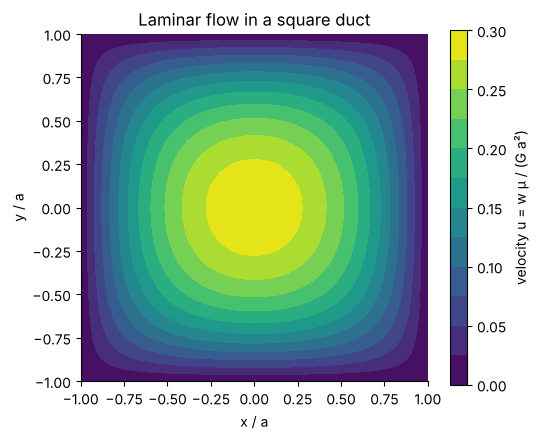

In [17]:
x_full = cheb(48)[1]
U_full = np.zeros((49, 49))
U_full[1:48, 1:48] = U                                             # put the zero wall values back for plotting
fig, ax = plt.subplots(figsize=(5.6, 4.6))
filled = ax.contourf(x_full, x_full, U_full, levels=np.linspace(0, 0.3, 13), cmap="viridis")
fig.colorbar(filled, ax=ax, label="velocity u = w μ / (G a²)")
ax.set(xlabel="x / a", ylabel="y / a", aspect="equal", title="Laminar flow in a square duct")
ax.grid(False)

The spectral solution gives $Q = 0.562308$, a centre velocity of $0.294685$ and
$f\,Re = 14.2271$, the value found in every table of laminar duct flow. For a circular pipe
the product is 16. Using the pipe formula with the hydraulic diameter, a common shortcut,
would overestimate the pressure drop of a square duct by 12 %. The same equation describes the
torsion of a square bar, where $4Q = 2.2492$ is the torsion constant in units of $a^4$.

**A note on the convergence.** Doubling $N$ from 8 to 16 reduced the error by a factor of about
$2^8$: fast, but **algebraic**, not geometric. The cause is the corners. The equation asks for
$u_{xx} + u_{yy} = -1$ at a corner, while $u = 0$ along both walls forces both second
derivatives to vanish there, so the solution has a weak singularity at each corner. It is
weak enough that 15 points per direction already give seven digits. Notebook 16 returns
to corner singularities.

**A note on cost.** The matrix $L$ has $(N-1)^2$ rows and columns and is dense enough that we
stored it in full: $(N-1)^4$ numbers, and a solution time that grows like $N^6$. That is
comfortable up to $N$ of 40 to 60 (at $N = 48$ the matrix has 4.9 million entries) and
hopeless at $N = 200$. Since spectral accuracy rarely needs more than a few dozen points per
direction, the simple approach goes a long way.

## Summary

- Replace derivatives by differentiation matrices and the differential equation becomes a
  linear system. Dirichlet conditions remove the boundary unknowns: keep `A[1:N, 1:N]`.
- Index 0 is $x = +1$ and index $N$ is $x = -1$. Non-zero boundary values move to the
  right-hand side, multiplied by their columns.
- A variable coefficient is a diagonal matrix: $(k u')'$ becomes `D @ np.diag(k) @ D`.
- Nonlinear problems are solved by Newton's method, a sequence of linear boundary value
  problems. Quadratic convergence of the residual confirms the Jacobian.
- A solution curve with a turning point is followed by prescribing a quantity that varies
  steadily along it and treating the parameter as an unknown.
- In two dimensions the Laplacian is `np.kron(I, D2) + np.kron(D2, I)`, with the unknowns
  ordered row by row.

## Exercises

1. A rod of length 1 joins two walls. Its temperature excess satisfies $\theta'' = m^2\theta$
   on $0 \le x \le 1$ with $\theta(0) = 1$, $\theta(1) = 0.2$ and $m = 3$. Map the Chebyshev
   points to $[0, 1]$ (the second-derivative matrix is multiplied by 4), solve with $N = 16$
   and compute the heat flow into the rod at the hot end, $-\theta'(0)$. Check against the
   exact solution, a combination of $\sinh mx$ and $\sinh m(1-x)$.
2. Steady convection and diffusion of a solute between two reservoirs obeys
   $u'' - Pe\,u' = 0$ on $[-1, 1]$ with $u(-1) = 0$ and $u(1) = 1$. The exact solution is
   $u = \big(e^{Pe\,(x-1)} - e^{-2Pe}\big)/\big(1 - e^{-2Pe}\big)$, which has a boundary layer of thickness
   $1/Pe$ at $x = 1$. For $Pe = 10$ and $Pe = 50$ find the smallest even $N$ that gives a largest
   error below $10^{-8}$. Plot the solution for $Pe = 50$ with $N = 16$ and describe what an
   under-resolved spectral solution looks like.
3. For a second-order reaction in the catalyst slab the equation becomes
   $\theta'' = \phi^2\theta^2$, $\theta(\pm1) = 1$. Solve it by Newton's method for $\phi = 2$
   with $N = 32$, starting from $\theta = 1$, and print the residuals. Report the effectiveness
   factor $\eta = \theta'(1)/\phi^2$ and check your solution with the identity
   $\theta'(1)^2 = \tfrac23\phi^2\big(1 - \theta(0)^3\big)$, which follows from multiplying the
   equation by $\theta'$ and integrating.
4. With the full Arrhenius rate the thermal explosion problem is
   $u'' + \delta\exp\!\big(u/(1 + \varepsilon u)\big) = 0$, $u(\pm1) = 0$, where $\varepsilon$
   is the ambient temperature in units of the activation temperature. Adapt `bratu_centre` to
   this heat source and trace $\delta$ against $u(0)$ for $0.05 \le u(0) \le 60$ with $N = 40$. For
   $\varepsilon = 0.2$ find both turning points (ignition and extinction) to four digits. For
   $\varepsilon = 0.3$ show that there is no turning point, and say what that means for the
   material.
5. A rectangular duct has sides $4a$ and $2a$. Solve $\nabla^2 u = -1$ on
   $[-2, 2]\times[-1, 1]$ with $u = 0$ on the walls by rescaling the $x$ derivative, and
   compute $f\,Re$ based on the hydraulic diameter. The tabulated value is 15.548.